# Phân loại Spam/Ham bình luận sinh viên PTIT

**Thực nghiệm và ứng dụng — Nhóm Bảo, Cương, Phi, Phương**

Notebook trình bày quy trình xử lý văn bản, biểu diễn đặc trưng, huấn luyện và
đánh giá mô hình phân loại. Dữ liệu thực nghiệm sử dụng phiên bản `v7`.

Thực hiện các cell theo thứ tự trong môi trường Python 3.12 của project.


## 1. Cấu hình môi trường

Kiểm tra phiên bản thư viện, thiết lập đường dẫn dữ liệu và thư mục kết quả.
Seed được cố định để hỗ trợ tái lập thí nghiệm.


In [1]:
import os, sys
import importlib.metadata as metadata

assert sys.version_info[:2] == (3, 12), "Chọn kernel Python 3.12 trong .venv của project."
PACKAGES = {
    "numpy": "1.26.4", "scipy": "1.13.1", "pandas": "2.2.3",
    "scikit-learn": "1.6.1", "matplotlib": "3.10.3", "joblib": "1.5.1",
    "gensim": "4.4.0", "underthesea": "8.3.0", "jinja2": "3.1.6",
}
ENVIRONMENT = {name: metadata.version(name) for name in PACKAGES}
assert ENVIRONMENT == PACKAGES, "Cài requirements/notebook.txt bằng Python trong .venv rồi restart kernel."
print("Phiên bản thư viện khớp cấu hình thực nghiệm.")


Phiên bản thư viện khớp cấu hình thực nghiệm.


In [2]:
import os, sys
from pathlib import Path

# Xác định thư mục gốc để nạp các module của project.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "pipeline/__init__.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Mở notebook trong thư mục project có pipeline/ và external/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json, time, tempfile
import inspect
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown
from pipeline.presentation.notebook_display import display_readable as display
from joblib import Memory
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix, precision_recall_curve)

SEED = 42
np.random.seed(SEED)
N_JOBS = int(os.environ.get("SPAMHAM_N_JOBS", "2"))
ARTIFACT_DIR = Path(os.environ.get("SPAMHAM_OUTPUT_DIR", str(PROJECT_ROOT / "artifacts/spamham")))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = Path(os.environ.get("SPAMHAM_CSV", str(PROJECT_ROOT / "data/final/labeled_v7.csv")))
PROCESSED_PATH = PROJECT_ROOT / "data/processed/v7_preprocessed.csv"
pd.set_option("display.max_colwidth", 100)
print("Python:", sys.version.split()[0], "| jobs:", N_JOBS)
display(pd.Series(ENVIRONMENT, name="version").to_frame())


Python: 3.12.14 | jobs: 2


#,version
numpy,1.26.4
scipy,1.13.1
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.3
joblib,1.5.1
gensim,4.4.0
underthesea,8.3.0
jinja2,3.1.6


In [3]:
from pipeline.features.spam_features import FastTextVectorizer
from pipeline.prepare import preprocess_for_model as preprocessing_module
from pipeline.features import spam_features as features_module
from pipeline.prepare.preprocess_for_model import preprocess, STOP_WORDS
from pipeline.modeling.training_utils import (norm_key, bucket, grouped_folds, undersampled_search,
                                              tune_nb_threshold, predict_record, sample_training_indices)
from pipeline.modeling.experiments import FEATURES, MODELS, make_pipe, fit_experiment, evaluate, boot_ci
from pipeline.inference.predict import predict_spam


## 2. Khảo sát dữ liệu

Đọc trực tiếp `data/final/labeled_v7.csv`. Hai nhãn gồm **ham** — bình luận thông
thường và **spam** — nội dung rác hoặc chào mời. Khảo sát số mẫu, phân bố nhãn,
độ dài và loại bình luận; kiểm tra ID, văn bản rỗng và các nội dung lặp.

Bảng trích 6 bình luận cho mỗi nhãn từ chính file dữ liệu, giữ ID để đối chiếu.
Các biểu đồ và thống kê được tính trên toàn bộ tập dữ liệu.


In [4]:
raw = pd.read_csv(CSV_PATH, keep_default_na=False, dtype={"id": str})
raw["label"] = raw["label"].str.strip().str.lower()
assert raw.id.is_unique and raw.id.str.strip().ne("").all(), "ID phải duy nhất và không rỗng."
assert set(raw.label) == {"ham", "spam"}, "Dữ liệu cần hai nhãn ham/spam."
assert raw.cleaned_text.str.strip().ne("").all(), "cleaned_text không được rỗng."

y_all = raw.label.eq("spam").astype(int).to_numpy()
exact_keys = raw.cleaned_text.str.normalize("NFC").str.lower().str.strip()
DATA_AUDIT = {
    "rows": len(raw), "labels": raw.label.value_counts().to_dict(),
    "duplicate_ids": int(raw.id.duplicated().sum()),
    "empty_cleaned_text": int(raw.cleaned_text.str.strip().eq("").sum()),
    "rows_in_repeated_text_groups": int(exact_keys.duplicated(keep=False).sum()),
    "text_groups_with_conflicting_labels": int((raw.groupby(exact_keys).label.nunique() > 1).sum()),
}
distribution = raw.label.value_counts().rename("Số bình luận").to_frame()
distribution["Tỷ lệ (%)"] = (distribution["Số bình luận"] / len(raw) * 100).round(2)
display(pd.Series(DATA_AUDIT, name="Thống kê").to_frame())
display(distribution)
preview_indices = raw.groupby("label").sample(n=6, random_state=SEED).index
display(raw.loc[preview_indices, ["id", "label", "text", "cleaned_text", "comment_type", "reaction_count"]])


#,Thống kê
rows,38233
labels,"{'ham': 32907, 'spam': 5326}"
duplicate_ids,0
empty_cleaned_text,0
rows_in_repeated_text_groups,2729
text_groups_with_conflicting_labels,27


label,Số bình luận,Tỷ lệ (%)
ham,32907,86.07
spam,5326,13.93


#,id,label,text,cleaned_text,comment_type,reaction_count
24256,cmt_25447,ham,Chắc đc. Hạn đến hết ngày 24/8 mà,Chắc đc. Hạn đến hết ngày 24 8 mà,comment,1
14203,cmt_14817,ham,Rõ ràng,Rõ ràng,comment,0
14358,cmt_14993,ham,Im luôn ạ,Im luôn ạ,comment,1
4799,cmt_4919,ham,Hieu Duc chịu,Hieu Duc chịu,reply,0
5020,cmt_5150,ham,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,reply,0
21683,cmt_22788,ham,"t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc","t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc",comment,1
20881,cmt_21963,spam,.,.,comment,0
35596,p2_cmt_3879,spam,Ph Tr Đức em vô nhóm c ghim đầu nhen,Ph Tr Đức em vô nhóm c ghim đầu nhen,reply,0
35835,p2_cmt_4175,spam,Trần Việt Đức e add và rep str c nhậnn nha,Trần Việt Đức e add và rep str c nhậnn nha,reply,0
21093,cmt_22180,spam,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee🤩,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee,comment,0


label,count,mean,std,min,25%,50%,75%,max
ham,32907.0,11.3,13.3,1.0,5.0,8.0,13.0,667.0
spam,5326.0,13.6,24.3,1.0,2.0,6.0,12.0,315.0


comment_type,ham,spam
comment,0.842,0.158
reply,0.89,0.11


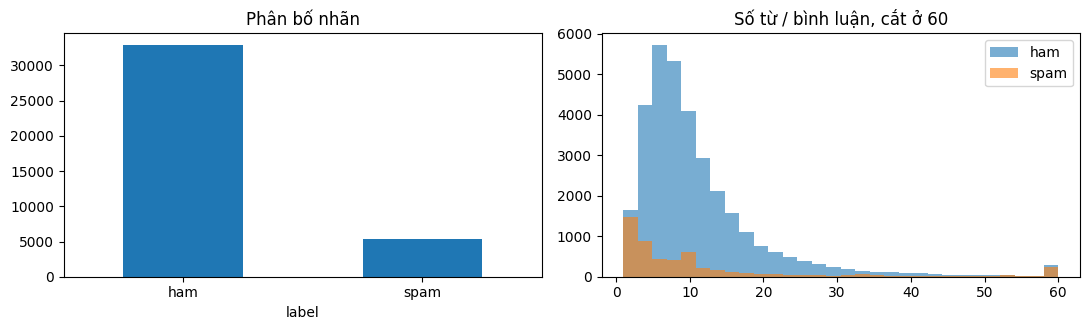

In [5]:
raw["n_words"] = raw["cleaned_text"].str.split().str.len()
display(raw.groupby("label")["n_words"].describe().round(1))
display(pd.crosstab(raw["comment_type"], raw["label"], normalize="index").round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
raw["label"].value_counts().plot.bar(ax=ax[0], rot=0, title="Phân bố nhãn")
for label in ["ham", "spam"]:
    ax[1].hist(raw.loc[raw.label == label, "n_words"].clip(upper=60), bins=30, alpha=.6, label=label)
ax[1].set_title("Số từ / bình luận, cắt ở 60"); ax[1].legend()
plt.tight_layout(); plt.show()


## 3. Tiền xử lý văn bản

Thực hiện trên toàn bộ bình luận trong v7. Giữ `text` gốc và `cleaned_text` có sẵn;
chuẩn hóa đầu vào mô hình, xử lý tên/URL/điện thoại/emoji, chuyển chữ thường và
tách từ tiếng Việt bằng underthesea. Các từ phủ định được giữ lại.

Tạo hai cột token tương ứng với cấu hình giữ và loại stop words. Lưu toàn bộ
kết quả vào `data/processed/v7_preprocessed.csv`, đọc lại và sử dụng các cột này
trong các bước huấn luyện tiếp theo. Bảng trước/sau dùng cùng ID bình luận ở mục 2.

Nhánh giữ stop words là đối chứng bổ sung để lựa chọn cấu hình tiền xử lý bằng
cross-validation. Bảng so sánh chi tiết được đặt ở phụ lục để phần chính tập
trung vào xây dựng mô hình và đánh giá phân loại.


In [6]:
t0 = time.time()
prepared = raw[["id", "label", "text", "cleaned_text", "comment_type", "reaction_count"]].copy()
prepared["tokens_keep_stopwords"] = [preprocess(c, t, False) for c, t in zip(raw.cleaned_text, raw.text)]
prepared["tokens_remove_stopwords"] = prepared.tokens_keep_stopwords.map(
    lambda text: " ".join(token for token in text.split() if token not in STOP_WORDS))

PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
prepared.to_csv(PROCESSED_PATH, index=False, encoding="utf-8-sig")
prepared = pd.read_csv(PROCESSED_PATH, keep_default_na=False, dtype={"id": str})
assert prepared.id.tolist() == raw.id.tolist() and prepared.label.tolist() == raw.label.tolist()
TEXT = {"giữ stop words": prepared.tokens_keep_stopwords,
        "có loại stop words": prepared.tokens_remove_stopwords}

display(prepared.loc[preview_indices, ["id", "label", "text", "cleaned_text",
                                      "tokens_keep_stopwords", "tokens_remove_stopwords"]])
print(f"Đã xử lý và lưu {len(prepared):,} bình luận trong {time.time()-t0:.1f}s.")
print("File:", PROCESSED_PATH.relative_to(PROJECT_ROOT).as_posix())


#,id,label,text,cleaned_text,tokens_keep_stopwords,tokens_remove_stopwords
24256,cmt_25447,ham,Chắc đc. Hạn đến hết ngày 24/8 mà,Chắc đc. Hạn đến hết ngày 24 8 mà,chắc đc . hạn đến hết ngày 24 8 mà,chắc đc . hạn hết ngày 24 8
14203,cmt_14817,ham,Rõ ràng,Rõ ràng,rõ_ràng,rõ_ràng
14358,cmt_14993,ham,Im luôn ạ,Im luôn ạ,im luôn ạ,im
4799,cmt_4919,ham,Hieu Duc chịu,Hieu Duc chịu,hieu duc chịu,hieu duc chịu
5020,cmt_5150,ham,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,Xuân Nhật a ơi thầy Hùng cho điểm thấp lắm ạ,xuân nhật_a ơi thầy_hùng cho điểm thấp lắm ạ,xuân nhật_a thầy_hùng điểm thấp
21683,cmt_22788,ham,"t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc","t cũng như b nè về mang ra bí thư khu phố hoặc xã phường ấy b, ngta đóng dấu cho là đc","t cũng như b nè về mang ra bí_thư khu_phố hoặc xã_phường ấy b , ngta đóng_dấu cho là đc","t b mang bí_thư khu_phố xã_phường b , ngta đóng_dấu đc"
20881,cmt_21963,spam,.,.,.,.
35596,p2_cmt_3879,spam,Ph Tr Đức em vô nhóm c ghim đầu nhen,Ph Tr Đức em vô nhóm c ghim đầu nhen,ph tr_đức em vô nhóm c ghim đầu nhen,ph tr_đức em vô nhóm c ghim đầu nhen
35835,p2_cmt_4175,spam,Trần Việt Đức e add và rep str c nhậnn nha,Trần Việt Đức e add và rep str c nhậnn nha,user_name e_add và rep str c nhậnn nha,user_name e_add rep str c nhậnn
21093,cmt_22180,spam,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee🤩,Còn Câu lạc bộ Sách và Hành động PTIT mở đơn nốt hôm nay nhee,còn câu_lạc_bộ sách và hành_động ptit mở đơn nốt hôm_nay nhee emoji_token,câu_lạc_bộ sách hành_động ptit mở đơn nốt hôm_nay nhee emoji_token


Đã xử lý và lưu 38,233 bình luận trong 20.9s.
File: data/processed/v7_preprocessed.csv


## 4. Thiết kế thực nghiệm

Chia train/test theo nhóm văn bản đã chuẩn hóa, với tỷ lệ xấp xỉ 80/20.
Các nội dung có cùng khóa được giữ trong cùng nhóm. Cross-validation gồm 5 fold
trên tập train; kiểm tra nhóm không giao nhau và mỗi tập có đủ hai lớp.

Siêu tham số, cấu hình stop words và mô hình được lựa chọn bằng cross-validation.
Tập test dùng để đánh giá các cấu hình đã xác định. Thiết kế này kiểm soát trùng
lặp theo khóa văn bản, chưa loại trừ mọi quan hệ gần trùng hoặc ngữ cảnh chung.


In [7]:
keys = raw["cleaned_text"].map(norm_key).to_numpy()
is_test = np.array([bucket(key, "test") == 0 for key in keys])
train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
y_train, y_test = y_all[train_idx], y_all[test_idx]
assert len(np.unique(y_train)) == len(np.unique(y_test)) == 2
assert not set(keys[train_idx]) & set(keys[test_idx])
CV_FOLDS = grouped_folds(keys[train_idx], y_train)
fold_table = pd.DataFrame([{"fold": i + 1, "train": len(tr), "validation": len(va),
                            "spam_validation": int(y_train[va].sum())} for i, (tr, va) in enumerate(CV_FOLDS)])
display(fold_table)
print(f"Train {len(train_idx)} ({y_train.mean():.1%} spam); test {len(test_idx)} ({y_test.mean():.1%} spam)")
print(f"Baseline toàn ham: Accuracy={1-y_test.mean():.4f}, Recall/F1 spam=0")

train_counts = pd.Series(np.where(y_train == 1, "spam", "ham")).value_counts().rename("Số mẫu train").to_frame()
train_counts["Tỷ lệ (%)"] = (train_counts["Số mẫu train"] / len(y_train) * 100).round(2)
train_counts["Trọng số balanced"] = len(y_train) / (2 * train_counts["Số mẫu train"])
display(train_counts.round(4))


#,fold,train,validation,spam_validation
0,1,24815,5944,764
1,2,24327,6432,1187
2,3,24554,6205,856
3,4,24529,6230,789
4,5,24811,5948,779


Train 30759 (14.2% spam); test 7474 (12.7% spam)
Baseline toàn ham: Accuracy=0.8728, Recall/F1 spam=0


#,Số mẫu train,Tỷ lệ (%),Trọng số balanced
ham,26384,85.78,0.5829
spam,4375,14.22,3.5153


## 5. Xây dựng và huấn luyện mô hình

Ba phương pháp biểu diễn **BoW, TF-IDF, FastText** được kết hợp với hai họ thuật
toán **Naive Bayes, SVM**, tạo thành 6 cặp đặc trưng–thuật toán. Mỗi cặp được
thực nghiệm với hai cấu hình stop words, tương ứng 12 lần lựa chọn mô hình bằng CV.
Đối chứng stop words được tổng hợp trong phụ lục.

BoW/TF-IDF sử dụng MultinomialNB hoặc LinearSVC. FastText sử dụng GaussianNB hoặc
StandardScaler kết hợp LinearSVC; GaussianNB phù hợp với embedding có giá trị âm.
Từ vựng, IDF và embedding được học trong phần train của từng fold.


In [8]:
# Grid/cấu hình nằm ở pipeline/modeling/experiments.py: make_pipe().
# Fit vectorizer và model trong train của từng fold, không fit trên test.
cache_dir = tempfile.TemporaryDirectory(prefix="spamham_cache_", dir=ARTIFACT_DIR)
cache = Memory(cache_dir.name, verbose=0)
RESULTS = []
for pre in TEXT:
    X_train_text = TEXT[pre].iloc[train_idx].to_numpy()
    for feature in FEATURES:
        for algorithm in MODELS:
            result = fit_experiment(pre, feature, algorithm, X_train_text, y_train, CV_FOLDS,
                                    seed=SEED, cache=cache, n_jobs=N_JOBS)
            RESULTS.append(result)
            print(pre, feature, algorithm, f"CV F1={result['CV F1 (spam)']:.4f}", result["Tham số"], flush=True)


giữ stop words BoW Naive Bayes CV F1=0.6077 {'clf__alpha': 1.0, 'vec__ngram_range': (1, 2)}


giữ stop words BoW SVM CV F1=0.7091 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}


giữ stop words TF-IDF Naive Bayes CV F1=0.5959 {'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}


giữ stop words TF-IDF SVM CV F1=0.7736 {'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}


giữ stop words FastText Naive Bayes CV F1=0.5594 {'clf__var_smoothing': 0.001, 'vec__pooling': 'tfidf'}


giữ stop words FastText SVM CV F1=0.6794 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}


... (2 outputs left out)

có loại stop words TF-IDF Naive Bayes CV F1=0.5835 {'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}


có loại stop words TF-IDF SVM CV F1=0.7562 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}


có loại stop words FastText Naive Bayes CV F1=0.4894 {'clf__var_smoothing': 0.001, 'vec__pooling': 'mean'}


có loại stop words FastText SVM CV F1=0.6653 {'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}


### 5.1. Xử lý mất cân bằng lớp

Ham chiếm đa số, nên Accuracy cần được đọc cùng Precision, Recall và F1 của spam.
Các thí nghiệm sử dụng **F1 spam trên cross-validation** để lựa chọn cấu hình.

Ba biện pháp được khảo sát thành **các nhánh riêng**, theo đặc điểm của mô hình:

- **Trọng số lớp cho SVM:** giữ nguyên dữ liệu, tăng mức phạt lỗi của lớp ít mẫu
  bằng `class_weight="balanced"`. Trọng số được tính lại từ phần train của mỗi
  lần fit: `n_samples / (n_classes × n_samples_of_class)`.
- **Under-sampling cho TF-IDF + SVM:** giữ các mẫu spam, chọn ngẫu nhiên tối đa
  2 mẫu ham trên mỗi mẫu spam từ phần train. Nhánh này dùng `class_weight=None`.
- **Chỉnh ngưỡng cho TF-IDF + Naive Bayes:** giữ nguyên dữ liệu, tìm ngưỡng bằng
  dự đoán ngoài fold trên train; so sánh với ngưỡng mặc định 0,5.

Trọng số được thử trong grid của các mô hình SVM. Các đối chứng chi tiết bên dưới
tập trung vào TF-IDF với cùng cấu hình tiền xử lý đã chọn. Ba biện pháp không được
áp dụng đồng thời lên mọi mô hình. Validation và test giữ phân bố nhãn tự nhiên;
chúng không tham gia việc lấy mẫu hoặc tìm ngưỡng.


Cấu hình tiền xử lý được chọn bằng CV: giữ stop words


#,Train gốc,Train sau under-sampling
ham,26384,8750
spam,4375,4375
Tổng,30759,13125


#,Mô hình,Nhánh,Dữ liệu train,Thay đổi
0,TF-IDF + SVM,Không điều chỉnh,Giữ nguyên,class_weight=None
1,TF-IDF + SVM,Trọng số balanced,Giữ nguyên,Tăng mức phạt lỗi theo lớp
2,TF-IDF + SVM,Under-sampling 2:1,Giảm ham trong train,class_weight=None
3,TF-IDF + Naive Bayes,Ngưỡng mặc định,Giữ nguyên,"Ngưỡng spam = 0,5"
4,TF-IDF + Naive Bayes,Chỉnh ngưỡng,Giữ nguyên,Chọn ngưỡng bằng OOF trên train


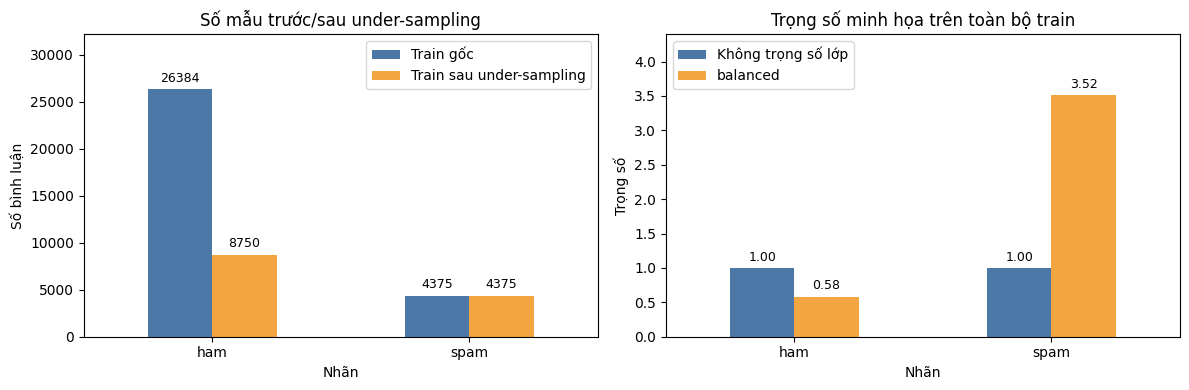

In [9]:
best_main = max(RESULTS, key=lambda r: r["CV F1 (spam)"])
MAIN_PRE = best_main["Tiền xử lý"]
print("Cấu hình tiền xử lý được chọn bằng CV:", MAIN_PRE)

sampled_preview = sample_training_indices(y_train, np.arange(len(y_train)), seed=SEED, ratio=2)
before_counts = pd.Series(np.where(y_train == 1, "spam", "ham")).value_counts().reindex(["ham", "spam"])
after_counts = pd.Series(np.where(y_train[sampled_preview] == 1, "spam", "ham")).value_counts().reindex(["ham", "spam"])
sampling_table = pd.DataFrame({"Train gốc": before_counts, "Train sau under-sampling": after_counts})
sampling_table.loc["Tổng"] = sampling_table.sum()
display(sampling_table)

scope = pd.DataFrame([
    {"Mô hình": "TF-IDF + SVM", "Nhánh": "Không điều chỉnh", "Dữ liệu train": "Giữ nguyên", "Thay đổi": "class_weight=None"},
    {"Mô hình": "TF-IDF + SVM", "Nhánh": "Trọng số balanced", "Dữ liệu train": "Giữ nguyên", "Thay đổi": "Tăng mức phạt lỗi theo lớp"},
    {"Mô hình": "TF-IDF + SVM", "Nhánh": "Under-sampling 2:1", "Dữ liệu train": "Giảm ham trong train", "Thay đổi": "class_weight=None"},
    {"Mô hình": "TF-IDF + Naive Bayes", "Nhánh": "Ngưỡng mặc định", "Dữ liệu train": "Giữ nguyên", "Thay đổi": "Ngưỡng spam = 0,5"},
    {"Mô hình": "TF-IDF + Naive Bayes", "Nhánh": "Chỉnh ngưỡng", "Dữ liệu train": "Giữ nguyên", "Thay đổi": "Chọn ngưỡng bằng OOF trên train"},
])
display(scope)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sampling_table.drop(index="Tổng").plot.bar(ax=axes[0], rot=0, color=["#4c78a8", "#f2a541"])
axes[0].set(title="Số mẫu trước/sau under-sampling", ylabel="Số bình luận", xlabel="Nhãn")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3, fontsize=9)
weights = pd.Series(len(y_train) / (2 * before_counts), name="balanced")
weight_table = pd.DataFrame({"Không trọng số lớp": [1.0, 1.0], "balanced": weights}, index=["ham", "spam"])
weight_table.plot.bar(ax=axes[1], rot=0, color=["#4c78a8", "#f2a541"])
axes[1].set(title="Trọng số minh họa trên toàn bộ train", ylabel="Trọng số", xlabel="Nhãn")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f", padding=3, fontsize=9)
axes[0].set_ylim(top=max(before_counts) * 1.22)
axes[1].set_ylim(top=max(weights) * 1.25)
plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "imbalance_training.png", dpi=140, bbox_inches="tight")
plt.show()


In [10]:
X_tr_text = TEXT[MAIN_PRE].iloc[train_idx].to_numpy()
SUPPLEMENTARY = []
# Hai nhánh cố định class weight: cùng grid C/ngram và cùng CV_FOLDS.
for weight in [None, "balanced"]:
    pipe, grid, jobs = make_pipe("TF-IDF", "SVM", seed=SEED, cache=cache, n_jobs=N_JOBS)
    grid["clf__class_weight"] = [weight]
    start = time.time()
    search = GridSearchCV(pipe, grid, scoring="f1", cv=CV_FOLDS,
                          n_jobs=N_JOBS, refit=True, error_score="raise").fit(X_tr_text, y_train)
    SUPPLEMENTARY.append({"Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "SVM",
        "Biến thể": f"class_weight={weight}", "CV F1 (spam)": search.best_score_,
        "Tham số": search.best_params_, "Thời gian (s)": time.time()-start, "_model": search.best_estimator_})

# OOF chỉ trong train; clone để không thay đổi model của thí nghiệm chính.
nb_record = next(r for r in RESULTS if r["Tiền xử lý"] == MAIN_PRE and r["Đặc trưng"] == "TF-IDF" and r["Thuật toán"] == "Naive Bayes")
start = time.time()
nb_model, nb_cv, threshold = tune_nb_threshold(nb_record["_model"], X_tr_text, y_train, CV_FOLDS)
SUPPLEMENTARY.append({"Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "Naive Bayes",
    "Biến thể": "chỉnh ngưỡng", "CV F1 (spam)": nb_cv,
    "Tham số": {**nb_record["Tham số"], "threshold": threshold}, "Thời gian (s)": time.time()-start,
    "_model": nb_model, "_threshold": threshold})

# Under-sampling chỉ trong train của mỗi fold; validation không bị lấy mẫu.
pipe, grid, _ = make_pipe("TF-IDF", "SVM", seed=SEED, cache=cache, n_jobs=N_JOBS)
grid["clf__class_weight"] = [None]
start = time.time()
us_model, us_cv, us_params, us_count = undersampled_search(pipe, grid, X_tr_text, y_train, CV_FOLDS, SEED)
SUPPLEMENTARY.append({"Tiền xử lý": MAIN_PRE, "Đặc trưng": "TF-IDF", "Thuật toán": "SVM",
    "Biến thể": "under-sampling 2:1", "CV F1 (spam)": us_cv, "Tham số": us_params,
    "Thời gian (s)": time.time()-start, "_model": us_model})
CANDIDATES = RESULTS + SUPPLEMENTARY
best = max(CANDIDATES, key=lambda r: r["CV F1 (spam)"])
print("Chọn theo CV trước đánh giá test:", {k: v for k, v in best.items() if not k.startswith("_")})
print("Under-sampling full train còn", us_count, "mẫu; ngưỡng NB", round(threshold, 4))

assert us_count == len(sampled_preview), "Số mẫu huấn luyện under-sampling phải khớp bảng minh họa."


Chọn theo CV trước đánh giá test: {'Tiền xử lý': 'giữ stop words', 'Đặc trưng': 'TF-IDF', 'Thuật toán': 'SVM', 'Biến thể': 'chính', 'CV F1 (spam)': 0.7735613299500151, 'Tham số': {'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}, 'Thời gian (s)': 17.334514617919922}
Under-sampling full train còn 13125 mẫu; ngưỡng NB 0.1721


### 5.2. Mô hình hiện đại

Phần triển khai mô hình hiện đại và so sánh với các mô hình cơ sở sẽ được bổ sung.


In [11]:
# Phần triển khai mô hình hiện đại sẽ được bổ sung tại đây.


## 6. Đánh giá mô hình

Báo cáo Accuracy, Precision, Recall, F1-score của lớp spam và Average Precision.
So sánh các phương pháp biểu diễn và thuật toán trên cùng thiết kế thực nghiệm.


In [12]:
for record in CANDIDATES:
    evaluate(record, TEXT[record["Tiền xử lý"]].iloc[test_idx].to_numpy(), y_test)
METRICS = ["Accuracy", "Precision", "Recall", "F1", "AP"]
REPORT_COLS = ["Tiền xử lý", "Đặc trưng", "Thuật toán", "Biến thể", "CV F1 (spam)", *METRICS, "Tham số", "Thời gian (s)"]
metrics = pd.DataFrame([{k: r[k] for k in REPORT_COLS} for r in CANDIDATES])
sel = [r for r in RESULTS if r["Tiền xử lý"] == MAIN_PRE]
display(metrics[(metrics["Tiền xử lý"] == MAIN_PRE) & (metrics["Biến thể"] == "chính")].round(4))
display(metrics[metrics["Biến thể"] != "chính"].round(4))
print("Mô hình cuối theo CV:", best["Đặc trưng"], best["Thuật toán"], best["Biến thể"], best["Tiền xử lý"])
print(f"Test F1={best['F1']:.4f}, Precision={best['Precision']:.4f}, Recall={best['Recall']:.4f}")


#,Tiền xử lý,Đặc trưng,Thuật toán,Biến thể,CV F1 (spam),Accuracy,Precision,Recall,F1,AP,Tham số,Thời gian (s)
0,giữ stop words,BoW,Naive Bayes,chính,0.6077,0.9141,0.7441,0.4953,0.5947,0.732,"{'clf__alpha': 1.0, 'vec__ngram_range': (1, 2)}",7.7122
1,giữ stop words,BoW,SVM,chính,0.7091,0.9241,0.711,0.6803,0.6953,0.7492,"{'clf__C': 1.0, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",425.9348
2,giữ stop words,TF-IDF,Naive Bayes,chính,0.5959,0.9257,0.8402,0.5142,0.638,0.7988,"{'clf__alpha': 0.1, 'vec__ngram_range': (1, 2)}",6.8139
3,giữ stop words,TF-IDF,SVM,chính,0.7736,0.9419,0.8818,0.6278,0.7334,0.8117,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",17.3345
4,giữ stop words,FastText,Naive Bayes,chính,0.5594,0.8493,0.4374,0.6425,0.5204,0.536,"{'clf__var_smoothing': 0.001, 'vec__pooling': 'tfidf'}",167.1182
5,giữ stop words,FastText,SVM,chính,0.6794,0.9253,0.8259,0.5237,0.6409,0.7179,"{'clf__C': 1.0, 'clf__class_weight': None, 'vec__pooling': 'mean'}",104.9286


#,Tiền xử lý,Đặc trưng,Thuật toán,Biến thể,CV F1 (spam),Accuracy,Precision,Recall,F1,AP,Tham số,Thời gian (s)
12,giữ stop words,TF-IDF,SVM,class_weight=None,0.7736,0.9419,0.8818,0.6278,0.7334,0.8117,"{'clf__C': 0.3, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",6.889
13,giữ stop words,TF-IDF,SVM,class_weight=balanced,0.758,0.9322,0.7139,0.7792,0.7451,0.8127,"{'clf__C': 0.1, 'clf__class_weight': 'balanced', 'vec__ngram_range': (1, 2)}",8.6477
14,giữ stop words,TF-IDF,Naive Bayes,chỉnh ngưỡng,0.7269,0.9249,0.6732,0.7971,0.7299,0.7988,"{'clf__alpha': 0.1, 'vec__ngram_range': (1, 2), 'threshold': 0.1721105527638191}",2.4655
15,giữ stop words,TF-IDF,SVM,under-sampling 2:1,0.7629,0.9394,0.7791,0.7308,0.7542,0.7826,"{'clf__C': 0.1, 'clf__class_weight': None, 'vec__ngram_range': (1, 2)}",9.0249


Mô hình cuối theo CV: TF-IDF SVM chính giữ stop words
Test F1=0.7334, Precision=0.8818, Recall=0.6278


### 6.1. Tác động của các cách xử lý mất cân bằng

So sánh trên cùng tập test, với các cấu hình đã lựa chọn bằng CV. Bảng báo cáo
Precision, Recall, F1 spam và số lỗi: **FP** là ham bị nhận nhầm thành spam,
**FN** là spam bị bỏ sót. Biểu đồ giúp quan sát sự đánh đổi giữa bắt được spam
và tăng cảnh báo nhầm.

Số mẫu train ghi cho mô hình fit cuối; riêng cross-validation, under-sampling
được thực hiện lại trong phần train của từng fold. Các chỉ số test phục vụ đánh
giá và phân tích; mô hình cuối được xác định bằng CV trước khi xem test.


Nhánh,Số mẫu train,Ngưỡng NB,CV F1 spam,Precision,Recall,F1,FP,FN
SVM gốc,30759,Không áp dụng,0.7736,0.8818,0.6278,0.7334,80,354
SVM balanced,30759,Không áp dụng,0.758,0.7139,0.7792,0.7451,297,210
SVM under-sampling,13125,Không áp dụng,0.7629,0.7791,0.7308,0.7542,197,256
"NB ngưỡng 0,5",30759,0.5,0.5959,0.8402,0.5142,0.638,93,462
NB chỉnh ngưỡng,30759,0.1721105527638191,0.7269,0.6732,0.7971,0.7299,368,193


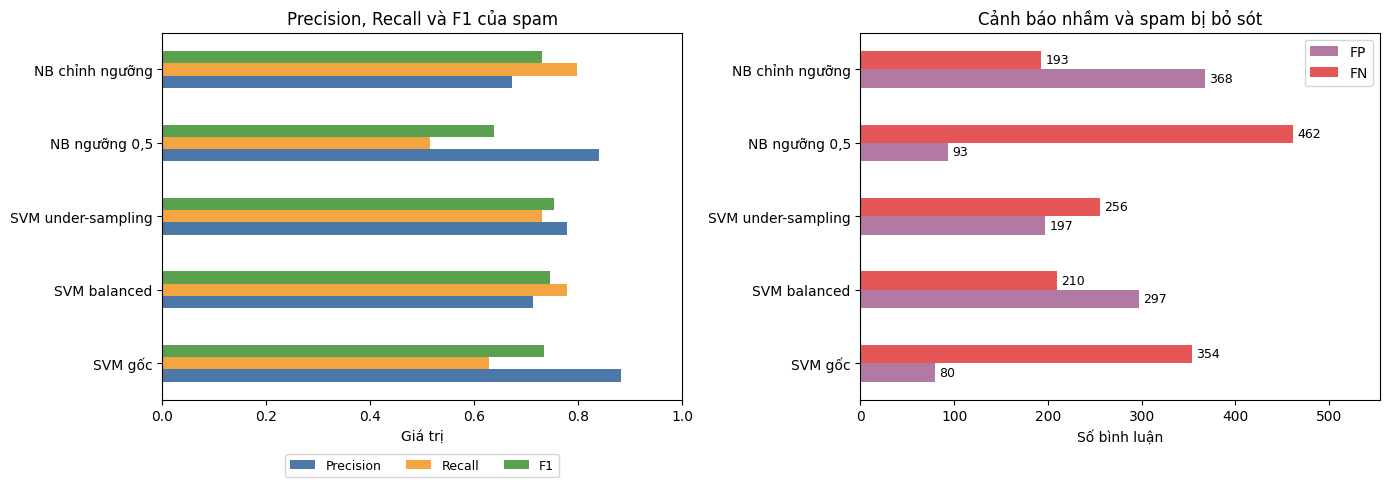

Lựa chọn theo CV: TF-IDF SVM chính | CV F1 spam = 0.7736


In [13]:
weight_base = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "class_weight=None")
weight_balanced = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "class_weight=balanced")
under_record = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "under-sampling 2:1")
tuned_record = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "chỉnh ngưỡng")
balance_records = [
    ("SVM gốc", weight_base, len(y_train), "Không áp dụng"),
    ("SVM balanced", weight_balanced, len(y_train), "Không áp dụng"),
    ("SVM under-sampling", under_record, us_count, "Không áp dụng"),
    ("NB ngưỡng 0,5", nb_record, len(y_train), 0.5),
    ("NB chỉnh ngưỡng", tuned_record, len(y_train), tuned_record["_threshold"]),
]
balance_rows = []
for label, record, train_rows, used_threshold in balance_records:
    tn, fp, fn, tp = confusion_matrix(y_test, record["_pred"], labels=[0, 1]).ravel()
    balance_rows.append({"Nhánh": label, "Số mẫu train": train_rows, "Ngưỡng NB": used_threshold,
        "CV F1 spam": record["CV F1 (spam)"], "Precision": record["Precision"],
        "Recall": record["Recall"], "F1": record["F1"], "FP": int(fp), "FN": int(fn)})
imbalance_report = pd.DataFrame(balance_rows).set_index("Nhánh")
display(imbalance_report.round(4))
imbalance_report.to_csv(ARTIFACT_DIR / "imbalance_comparison.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imbalance_report[["Precision", "Recall", "F1"]].plot.barh(ax=axes[0], color=["#4c78a8", "#f2a541", "#59a14f"])
axes[0].set(title="Precision, Recall và F1 của spam", xlabel="Giá trị", ylabel="", xlim=(0, 1))
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, fontsize=9)
imbalance_report[["FP", "FN"]].plot.barh(ax=axes[1], color=["#b279a2", "#e45756"])
axes[1].set(title="Cảnh báo nhầm và spam bị bỏ sót", xlabel="Số bình luận", ylabel="")
for container in axes[1].containers:
    axes[1].bar_label(container, padding=3, fontsize=9)
axes[1].set_xlim(right=imbalance_report[["FP", "FN"]].to_numpy().max() * 1.2)
plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "imbalance_results.png", dpi=140, bbox_inches="tight")
plt.show()
print("Lựa chọn theo CV:", best["Đặc trưng"], best["Thuật toán"], best["Biến thể"],
      "| CV F1 spam =", round(best["CV F1 (spam)"], 4))


### 6.2. Ma trận nhầm lẫn

Hàng thể hiện nhãn thực tế, cột thể hiện nhãn dự đoán. Phân biệt ham bị nhận nhầm
là spam (FP) và spam bị bỏ sót (FN).


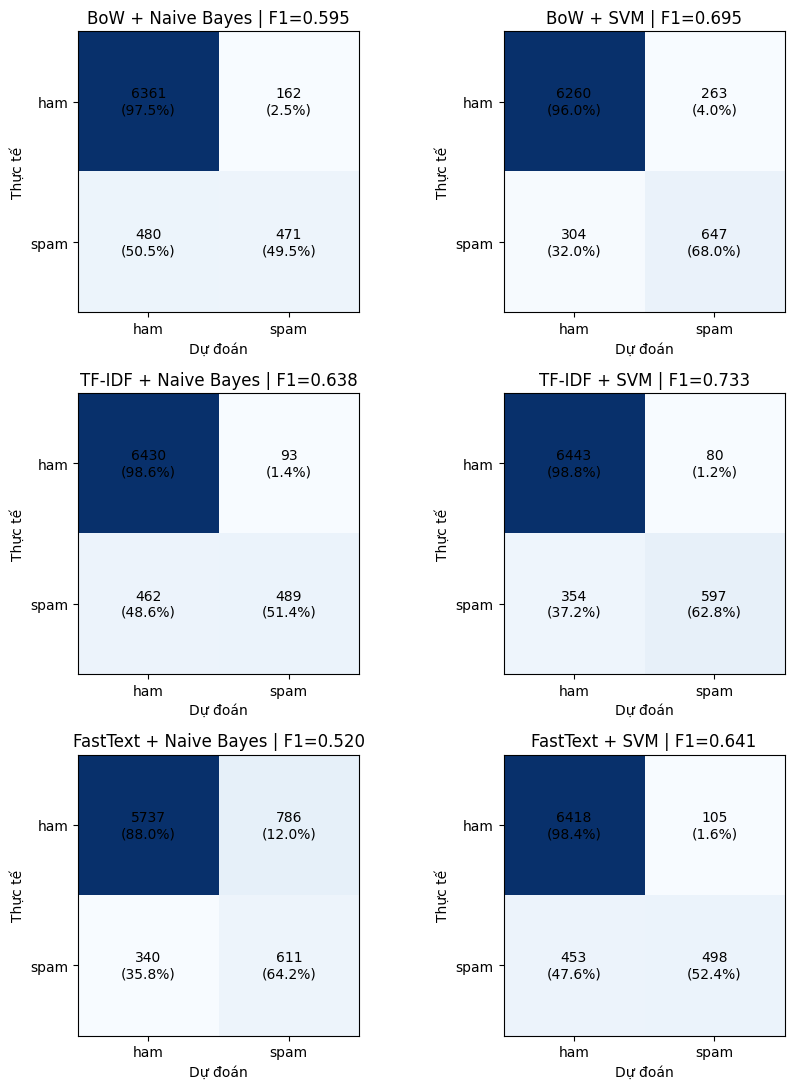

Confusion matrix mô hình cuối (kể cả nếu là thí nghiệm bổ sung):


#,đoán ham,đoán spam
thật ham,6443,80
thật spam,354,597


In [14]:
fig, axes = plt.subplots(3, 2, figsize=(9, 11))
for ax, record in zip(axes.ravel(), sel):
    matrix = confusion_matrix(y_test, record["_pred"], labels=[0, 1])
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i,j]}\n({matrix[i,j]/matrix[i].sum():.1%})", ha="center", va="center")
    ax.set_xticks([0, 1], ["ham", "spam"]); ax.set_yticks([0, 1], ["ham", "spam"])
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
    ax.set_title(f"{record['Đặc trưng']} + {record['Thuật toán']} | F1={record['F1']:.3f}")
plt.tight_layout(); plt.show()
print("Confusion matrix mô hình cuối (kể cả nếu là thí nghiệm bổ sung):")
display(pd.DataFrame(confusion_matrix(y_test, best["_pred"], labels=[0, 1]),
                     index=["thật ham", "thật spam"], columns=["đoán ham", "đoán spam"]))


### 6.3. Đường Precision–Recall và khoảng tin cậy F1

Bootstrap 500 lần theo dòng để mô tả biến động F1 trên tập test cố định.
Khoảng tin cậy cần được diễn giải cùng giới hạn phụ thuộc giữa các bình luận;
không sử dụng kết quả test để điều chỉnh lại mô hình.


#,Đặc trưng,Thuật toán,F1,CI thấp,CI cao
0,BoW,Naive Bayes,0.5947,0.5629,0.6227
1,BoW,SVM,0.6953,0.6724,0.7193
2,TF-IDF,Naive Bayes,0.638,0.6089,0.6655
3,TF-IDF,SVM,0.7334,0.7106,0.7562
4,FastText,Naive Bayes,0.5204,0.4969,0.5434
5,FastText,SVM,0.6409,0.6148,0.6663


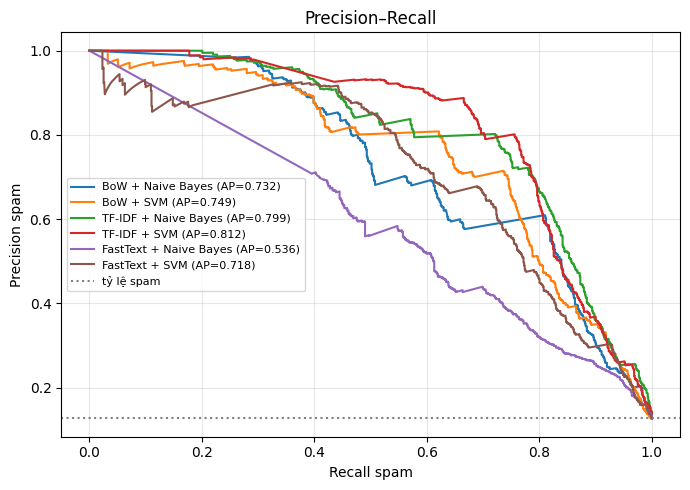

In [15]:
ci = []
for record in sel:
    lo, hi = boot_ci(y_test, record["_pred"])
    ci.append({"Đặc trưng": record["Đặc trưng"], "Thuật toán": record["Thuật toán"], "F1": record["F1"], "CI thấp": lo, "CI cao": hi})
display(pd.DataFrame(ci).round(4))
fig, ax = plt.subplots(figsize=(7, 5))
for record in sel:
    precision, recall, _ = precision_recall_curve(y_test, record["_score"])
    ax.plot(recall, precision, label=f"{record['Đặc trưng']} + {record['Thuật toán']} (AP={record['AP']:.3f})")
ax.axhline(y_test.mean(), ls=":", color="gray", label="tỷ lệ spam")
ax.set(xlabel="Recall spam", ylabel="Precision spam", title="Precision–Recall")
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()


## 7. Phân tích kết quả

Khảo sát các đặc trưng có trọng số lớn và các trường hợp FP/FN. Bình luận rất
ngắn hoặc phụ thuộc ngữ cảnh bài đăng có thể thiếu thông tin khi được phân loại
riêng lẻ. Các ví dụ lỗi được dùng để phân tích hành vi, không tự sửa nhãn.


In [16]:
tfidf_svm = next(r for r in sel if r["Đặc trưng"] == "TF-IDF" and r["Thuật toán"] == "SVM")
vec, clf = tfidf_svm["_model"].named_steps["vec"], tfidf_svm["_model"].named_steps["clf"]
names, coefficients = vec.get_feature_names_out(), clf.coef_.ravel()
order = np.argsort(coefficients)
print("Nghiêng về spam:", list(names[order[::-1][:20]]))
print("Nghiêng về ham:", list(names[order[:20]]))
errors = pd.DataFrame({"văn bản xử lý": TEXT[best["Tiền xử lý"]].iloc[test_idx].to_numpy(),
                       "thật": y_test, "đoán": best["_pred"], "score": best["_score"]})
print("FP:"); display(errors[(errors["thật"] == 0) & (errors["đoán"] == 1)].sort_values("score", ascending=False).head(10))
print("FN:"); display(errors[(errors["thật"] == 1) & (errors["đoán"] == 0)].sort_values("score").head(10))


Nghiêng về spam: ['urltoken', 'phonetoken', '.', 'ib chị', 'nhắn_c', 'user_name', 'chiến_lê', '…', 'nguyễn_hữu_trọng', 'aptis', 'mở đơn', ': urltoken', 'up community', 'community', 'emoji_token', 'ib c', 'linh_nhi', 'zalo', 'em vô', 'kỳ nam']
Nghiêng về ham: ['à', 'thôi', ': )', ': (', 'là', 'cảm_ơn', 'quá', 'kìa', 'cũng', 'phải', 'mà', 'vậy', 'thầy', 'đúng', 'ko', 'ạ emoji_token', 'hỏi', 'cô', 'rồi', 'đấy']
FP:


#,văn bản xử lý,thật,đoán,score
5260,user_name điên_k emoji_token,0,1,1.0101477983829592
1720,user_name poor emoji_token,0,1,1.0101477983829592
3666,user_name phonetoken b ib số này nha,0,1,0.9686141485207367
4686,chuyên_ngành thương_mại_điện_tử : d26cqtm01-b : urltoken d26cqtm02-b : urltoken d26cqtm03-b : urltoken emoji_token,0,1,0.9538239786248852
7233,em nhắn_c gửi nhne,0,1,0.8033513279219766
4941,em ib page hoặc nhắn_c nha,0,1,0.7138952076260332
5247,user_name đmm,0,1,0.6889058040182241
3345,user_name kìaa,0,1,0.6889058040182241
4276,user_name ýe,0,1,0.6889058040182241
5185,user_name nô,0,1,0.6889058040182241


FN:


#,văn bản xử lý,thật,đoán,score
4474,"mạn đó thì nhiều lắm b , qtrong b có tìm ra ttam uy_tín được hay k thôi , g ttam mọc lên như gì ấy mà , cần t rcm cho mấy ttam mà tham_khảo thì nhắn_t nhé",1,0,-1.3485047965054866
5573,chi yen có ạ,1,0,-1.333541346375513
1770,user_name toàn đi cắm r,1,0,-1.3288763603909697
3010,em xin vs a ơi,1,0,-1.2619072960920283
6712,36 k thì lấy,1,0,-1.2561829517066807
5234,đăng dươngg ib bạn này ạ hqua bạn em làm rơi,1,0,-1.2501957902789362
3807,nhat anh,1,0,-1.2428843608717424
743,martial the tks b nh,1,0,-1.2320128484809003
5615,user_name còn k b,1,0,-1.2245310934958662
5714,quá uy_tín,1,0,-1.220418795277654


### 7.1. Khảo sát embedding và từ ngoài từ vựng

FastText biểu diễn từ chưa gặp nhờ subword. Độ gần cosine có thể phản ánh hình
thức hoặc ngữ cảnh, không nhất thiết là quan hệ đồng nghĩa.


In [17]:
ft_svm = next(r for r in sel if r["Đặc trưng"] == "FastText" and r["Thuật toán"] == "SVM")
wv = ft_svm["_model"].named_steps["vec"].wv_
rows = []
for word in ["ib", "zalo", "lịch_thi", "inboxxx", "inb0x", "z.a.l.o"]:
    nearest = wv.most_similar(positive=[wv[word]], topn=5)
    rows.append({"từ": word, "có trong train": word in wv.key_to_index,
                 "vector gần nhất": ", ".join(f"{w} ({v:.2f})" for w, v in nearest)})
display(pd.DataFrame(rows))
only_ft = (y_test == 1) & (tfidf_svm["_pred"] == 0) & (ft_svm["_pred"] == 1)
only_tfidf = (y_test == 1) & (tfidf_svm["_pred"] == 1) & (ft_svm["_pred"] == 0)
print("Spam chỉ FastText bắt được:", int(only_ft.sum()), "| chỉ TF-IDF bắt được:", int(only_tfidf.sum()))


#,từ,có trong train,vector gần nhất
0,ib,True,"ib (1.00), ib_e (0.79), ibi (0.78), a_ib (0.75), ib_tớ (0.75)"
1,zalo,True,"zalo (1.00), valo (0.90), sdt (0.89), sđt (0.89), alo (0.88)"
2,lịch_thi,True,"lịch_thi (1.00), lịch_rảnh (0.90), lịch_sử (0.89), lịch_sự (0.89), lịch_k (0.89)"
3,inboxxx,False,"inbox (0.99), inb (0.92), jd (0.89), nerdbox (0.87), box (0.86)"
4,inb0x,False,"inb (0.97), inbox (0.94), valo (0.86), sdt (0.85), addfr (0.84)"
5,z.a.l.o,False,"kcn (0.88), hz (0.88), bùi_nhuận (0.87), series (0.87), instagram (0.86)"


Spam chỉ FastText bắt được: 33 | chỉ TF-IDF bắt được: 132


## 8. Lưu mô hình và dự đoán bình luận mới

Lưu mô hình đã huấn luyện cùng vectorizer, ngưỡng và cấu hình tiền xử lý trong
bundle `.joblib`. Kiểm tra dự đoán sau khi tải lại khớp với mô hình trong bộ nhớ.

Đầu vào ứng dụng là raw text. Với SVM, `score` là decision score; với Naive Bayes,
đó là xác suất lớp spam. Các câu minh họa không thay thế đánh giá trên tập test.


In [18]:
manifest = {"dataset_file": str(CSV_PATH), "processed_file": str(PROCESSED_PATH), "audit": DATA_AUDIT,
    "train_rows": len(train_idx), "test_rows": len(test_idx), "test_spam": int(y_test.sum()),
    "seed": SEED, "environment": ENVIRONMENT, "python": sys.version.split()[0],
    "completed_utc": datetime.now(timezone.utc).isoformat(), "modern_model": "not_implemented",
    "selected": {k: best[k] for k in ["Tiền xử lý", "Đặc trưng", "Thuật toán", "Biến thể", "CV F1 (spam)", *METRICS, "Tham số"]}}
bundle = {"model": best["_model"], "threshold": best.get("_threshold", 0.5),
    "remove_stop": best["Tiền xử lý"] == "có loại stop words", "manifest": manifest,
    "preprocessing_source": inspect.getsource(preprocessing_module),
    "features_source": inspect.getsource(features_module)}
# Cache chỉ phục vụ train; model cuối không phụ thuộc đường dẫn thư mục tạm.
for record in CANDIDATES:
    record["_model"].memory = None
model_path = ARTIFACT_DIR / "spam_ham_ml_only.joblib"
joblib.dump(bundle, model_path)
loaded = joblib.load(model_path)

X_verify = TEXT[best["Tiền xử lý"]].iloc[test_idx].to_numpy()
reloaded_pred, _ = predict_record({"_model": loaded["model"], "_threshold": loaded["threshold"]}, X_verify)
assert np.array_equal(reloaded_pred, best["_pred"])
display(predict_spam(["Cho mình hỏi lịch thi với ạ", "Liên hệ 0901234567 hoặc https://example.com", "Nguyễn Văn An", "."], loaded))
metrics.to_csv(ARTIFACT_DIR / "metrics.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(ci).to_csv(ARTIFACT_DIR / "bootstrap_ci.csv", index=False)
(ARTIFACT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
cache_dir.cleanup()
print("Đã kiểm tra load–predict khớp; metrics và manifest lưu ở", ARTIFACT_DIR)


#,text,score,score_type,du_doan
0,Cho mình hỏi lịch thi với ạ,-1.2542561405255837,decision_score,ham
1,Liên hệ 0901234567 hoặc https://example.com,2.968799201447487,decision_score,spam
2,Nguyễn Văn An,0.6889058040182241,decision_score,spam
3,.,0.9861020839940335,decision_score,spam


Đã kiểm tra load–predict khớp; metrics và manifest lưu ở C:\KH086\PT&KP DLVB\PROJECT\ptit-facebook-spam-ham\artifacts\spamham


## 9. Nhận xét

Tổng hợp cấu hình được lựa chọn, kết quả đánh giá và ảnh hưởng của cân bằng lớp.
Diễn giải hiệu năng cùng các giới hạn dữ liệu và ngữ cảnh bình luận.


In [19]:
base = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "class_weight=None")
balanced = next(r for r in SUPPLEMENTARY if r["Biến thể"] == "class_weight=balanced")
summary = f"""
- **Dữ liệu đánh giá:** {len(test_idx):,} bình luận; {int(y_test.sum()):,} mẫu spam.
- **Cấu hình lựa chọn bằng CV:** {best['Đặc trưng']} + {best['Thuật toán']} / {best['Biến thể']}, {best['Tiền xử lý']}.
- **Kết quả test:** Accuracy {best['Accuracy']:.2%}, Precision spam {best['Precision']:.2%},
  Recall spam {best['Recall']:.2%}, F1 spam {best['F1']:.4f}, AP {best['AP']:.4f}.
- **Ảnh hưởng class weight:** SVM không trọng số lớp có Recall {base['Recall']:.2%}, F1 {base['F1']:.4f};
  SVM balanced có Recall {balanced['Recall']:.2%}, F1 {balanced['F1']:.4f}.
- **Phạm vi xử lý:** trọng số SVM, under-sampling SVM và chỉnh ngưỡng NB là các nhánh riêng;
  validation/test giữ nguyên phân bố nhãn.
- **Giới hạn:** kết quả phụ thuộc nhãn hiện có và thông tin trong từng bình luận;
  các trường hợp ngắn hoặc cần ngữ cảnh có thể được phân loại chưa chính xác.
"""
display(Markdown(summary))



- **Dữ liệu đánh giá:** 7,474 bình luận; 951 mẫu spam.
- **Cấu hình lựa chọn bằng CV:** TF-IDF + SVM / chính, giữ stop words.
- **Kết quả test:** Accuracy 94.19%, Precision spam 88.18%,
  Recall spam 62.78%, F1 spam 0.7334, AP 0.8117.
- **Ảnh hưởng class weight:** SVM không trọng số lớp có Recall 62.78%, F1 0.7334;
  SVM balanced có Recall 77.92%, F1 0.7451.
- **Phạm vi xử lý:** trọng số SVM, under-sampling SVM và chỉnh ngưỡng NB là các nhánh riêng;
  validation/test giữ nguyên phân bố nhãn.
- **Giới hạn:** kết quả phụ thuộc nhãn hiện có và thông tin trong từng bình luận;
  các trường hợp ngắn hoặc cần ngữ cảnh có thể được phân loại chưa chính xác.


## Phụ lục A. Đối chứng stop words — thực nghiệm bổ sung

Đối chiếu cùng cặp đặc trưng–thuật toán trên hai cấu hình tiền xử lý. CV F1 spam
là tiêu chí lựa chọn; F1 test mô tả hiệu năng đánh giá. Cột chênh lệch được tính
bằng F1 test khi loại stop words trừ F1 test khi giữ stop words.

Thí nghiệm này giúp kiểm tra ảnh hưởng của việc loại các từ chức năng trong
bình luận ngắn. Chi tiết được tách khỏi phần đánh giá chính để tập trung vào
so sánh đặc trưng, thuật toán và các biện pháp xử lý mất cân bằng.


In [20]:
stopword_results = pd.DataFrame(RESULTS)
cv_stopwords = stopword_results.pivot(index=["Đặc trưng", "Thuật toán"], columns="Tiền xử lý", values="CV F1 (spam)")
test_stopwords = stopword_results.pivot(index=["Đặc trưng", "Thuật toán"], columns="Tiền xử lý", values="F1")
stopword_comparison = pd.DataFrame({
    "CV F1 giữ": cv_stopwords["giữ stop words"], "CV F1 loại": cv_stopwords["có loại stop words"],
    "Test F1 giữ": test_stopwords["giữ stop words"], "Test F1 loại": test_stopwords["có loại stop words"],
    "Chênh lệch loại − giữ": test_stopwords["có loại stop words"] - test_stopwords["giữ stop words"],
})
display(stopword_comparison.round(4))


#,CV F1 giữ,CV F1 loại,Test F1 giữ,Test F1 loại,Chênh lệch loại − giữ
"('BoW', 'Naive Bayes')",0.6077,0.5859,0.5947,0.593,-0.0017
"('BoW', 'SVM')",0.7091,0.6512,0.6953,0.6564,-0.0389
"('FastText', 'Naive Bayes')",0.5594,0.4894,0.5204,0.5341,0.0136
"('FastText', 'SVM')",0.6794,0.6653,0.6409,0.6238,-0.0171
"('TF-IDF', 'Naive Bayes')",0.5959,0.5835,0.638,0.5987,-0.0393
"('TF-IDF', 'SVM')",0.7736,0.7562,0.7334,0.7194,-0.014


## Tài liệu tham khảo

- Dataset PTIT: https://huggingface.co/datasets/p-storm/ptit-facebook-comments-spamham
- underthesea: https://github.com/undertheseanlp/underthesea
- scikit-learn: https://scikit-learn.org/stable/
- Gensim FastText: https://radimrehurek.com/gensim/models/fasttext.html
- Notebook tham khảo của nhóm: https://www.kaggle.com/code/itsmecuong/notebook82c07ebf7a
